# Example of the aitlas toolbox in the context of semantic segmentation

Note: The dataset structure is always modified to have images and labels folders.

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import VaihingenDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 33


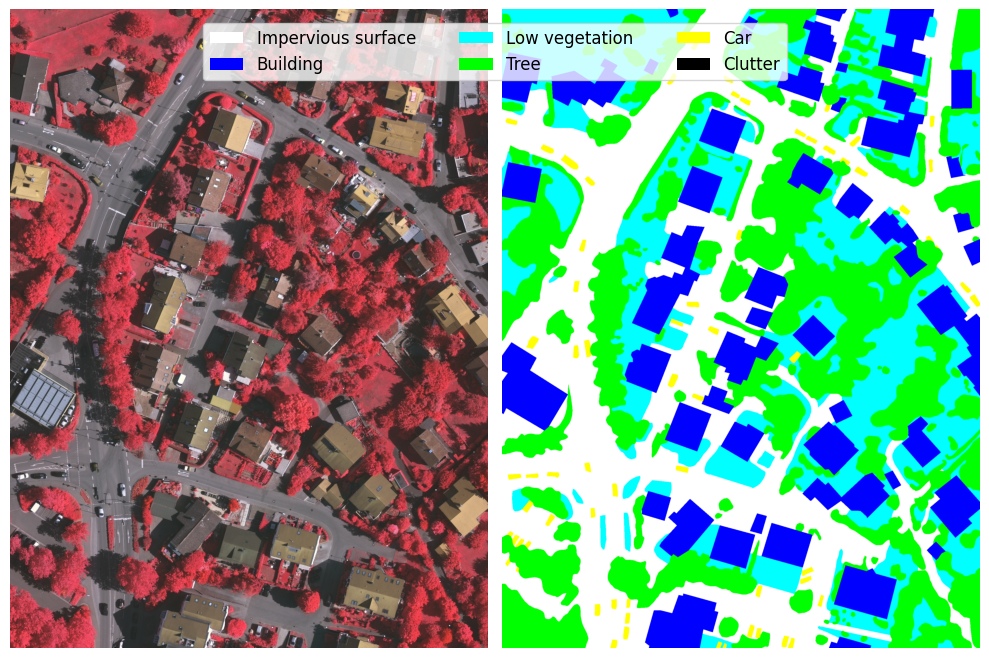

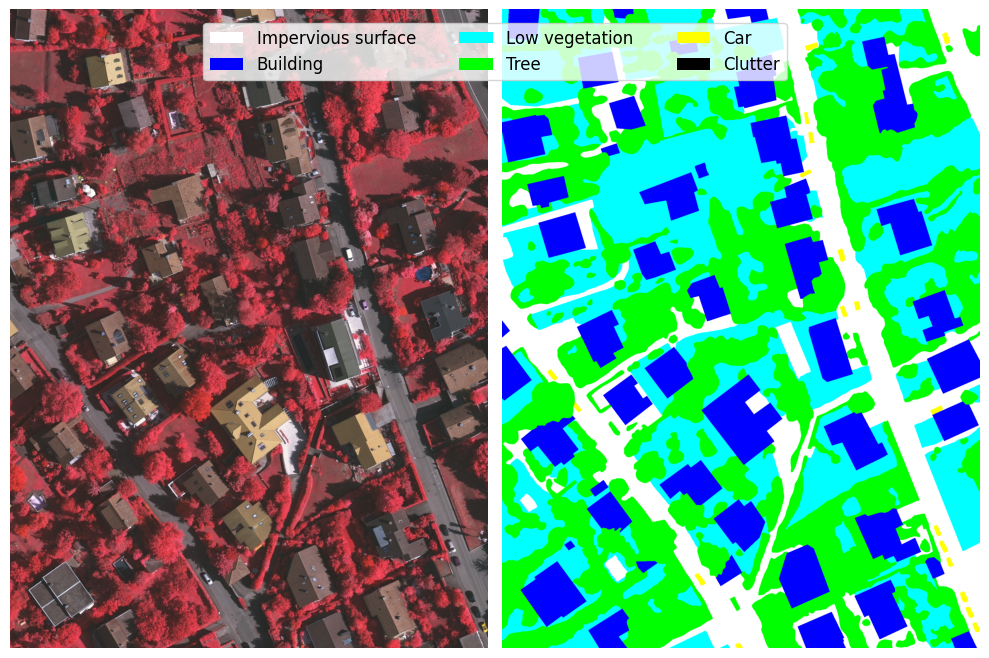

In [ ]:
dataset_config = {
    "data_dir": "./data/Vaihingen"
}
dataset = VaihingenDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(15);

In [4]:
dataset.data_distribution_table()

,Number of pixels
Impervious surface,48110427.0
Building,43779851.0
Low vegetation,35766767.0
Tree,38534748.0
Car,2096078.0
Clutter,0.0


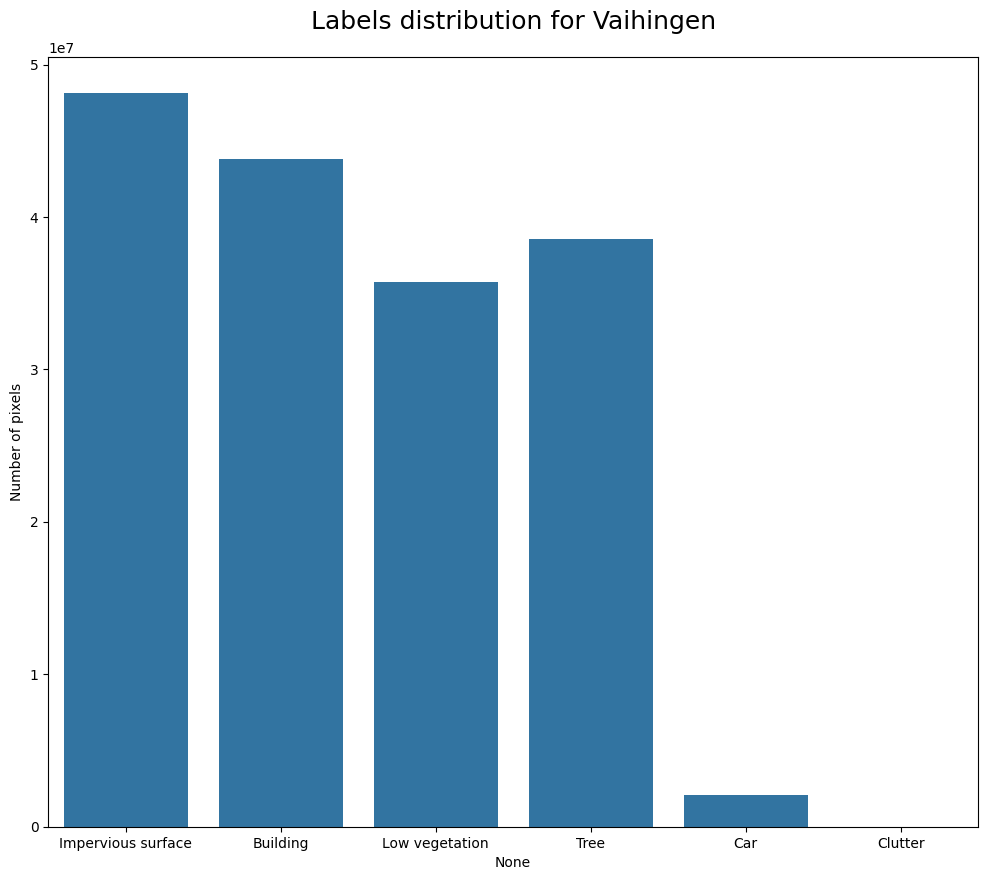

In [5]:
dataset.data_distribution_barchart();

## Load training data 

In [ ]:
train_dataset_config = {
    "batch_size": 3,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/Vaihingen",
    "csv_file": "./data/Vaihingen/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = VaihingenDataset(train_dataset_config)
len(train_dataset)

27

## Create the model 

In [ ]:
epochs = 10
model_directory = "./data/Vaihingen"
model_config = {
    "num_classes": 6, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-02-25 09:06:53,347 INFO Starting training.
training: 100%|██████████| 9/9 [10:47<00:00, 71.91s/it] 
2025-02-25 09:17:40,612 INFO epoch: 1, time: 647, loss:  0.74431
testing on train set: 100%|██████████| 9/9 [12:18<00:00, 82.01s/it] 
2025-02-25 09:30:00,854 INFO IOU:0.09200040315412314, IOU mean:0.053077628556108813, IOU per Class:[0.00168731 0.03626154 0.12799907 0.15164015 0.00087771 0.        ]
training: 100%|██████████| 9/9 [11:11<00:00, 74.64s/it] 
2025-02-25 09:41:12,647 INFO epoch: 2, time: 672, loss:  0.72439
testing on train set: 100%|██████████| 9/9 [10:36<00:00, 70.76s/it] 
2025-02-25 09:51:49,481 INFO IOU:0.12810296502055027, IOU mean:0.09969543494363332, IOU per Class:[0.13215504 0.15800009 0.13984252 0.16693198 0.00124299 0.        ]
training: 100%|██████████| 9/9 [12:25<00:00, 82.85s/it] 
2025-02-25 10:04:15,116 INFO epoch: 3, time: 746, loss:  0.70127
testing on train set: 100%|██████████| 9/9 [10:37<00:00, 70.88s/it] 
2025-02-25 10:14:53,042 INFO IOU:0.17379435572

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/Vaihingen",
    "csv_file": "./data/Vaihingen/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = VaihingenDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/Vaihingen/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

3


2025-02-25 12:57:14,507 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Vaihingen/checkpoint.pth.tar
2025-02-25 12:57:14,939 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Vaihingen/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 1/1 [03:10<00:00, 190.42s/it]


[{'IOU': 0.3640597990040369,
  'IOU mean': 0.2468726750970666,
  'IOU per Class': array([0.35894233, 0.50142588, 0.33454866, 0.28631918, 0.        ,
         0.        ])}]

## Predictions

2025-02-25 13:02:53,437 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Vaihingen/checkpoint.pth.tar
2025-02-25 13:02:53,839 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Vaihingen/checkpoint.pth.tar at epoch 11


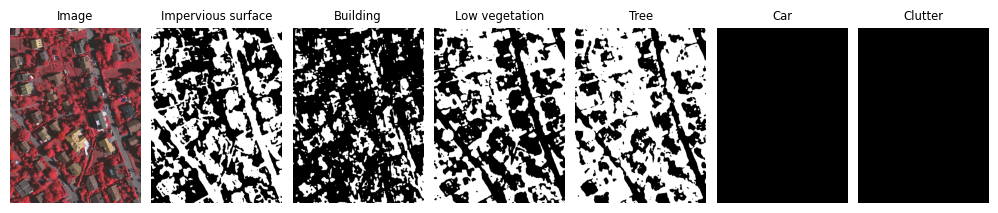

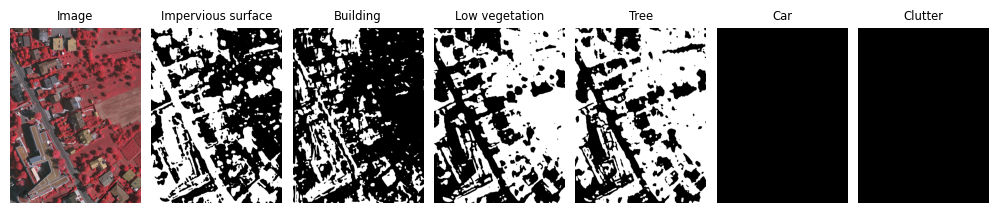

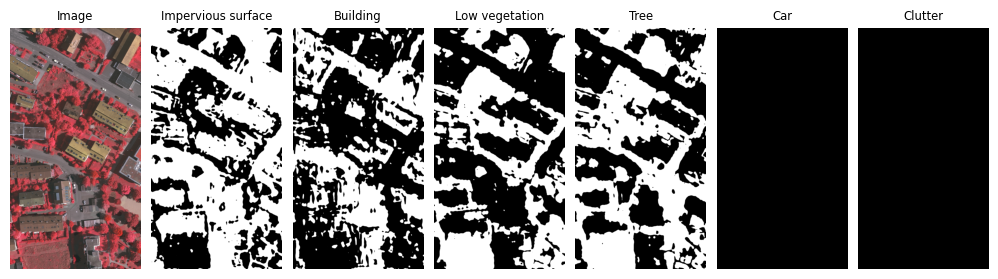

In [ ]:
model_path = "./data/Vaihingen/checkpoint.pth.tar"
labels = ["Impervious surface","Building","Low vegetation","Tree","Car","Clutter"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 7})
csv_file = "./data/Vaihingen/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/Vaihingen/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/Vaihingen/' + test_list[1])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/Vaihingen/' + test_list[2])
fig = model.predict_masks(image, labels, transform)